# Drug Galaxy: neighbor test

**Question:** do drugs that look alike treat the same conditions more often than chance?

Steps: load the data and fingerprints, find every drug's 10 closest look-alikes, measure how often they share a group, then compare against shuffled labels.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

drugs = pd.read_csv("../data/processed/drugs_clean.csv", keep_default_na=False)
drugs = drugs[drugs["heavy_atoms"] >= 6].reset_index(drop=True)

fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [fp_gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in drugs["smiles"]]
print("drugs:", len(drugs))

drugs: 2136


## 1. Groups for each drug

Each drug gets a **set** of its top-level ATC groups, e.g. ofloxacin → {J, S}. Rule: a neighbor counts as a match if it shares **any** group.

Only classified drugs are used in the test, since unclassified ones have nothing to match.

In [18]:

GROUP_NAMES = {
    "A": "Alimentary tract & metabolism", "B": "Blood", "C": "Cardiovascular",
    "D": "Dermatological", "G": "Genito-urinary & sex hormones", "H": "Hormones (non-sex)",
    "J": "Anti-infectives", "L": "Cancer & immune", "M": "Musculo-skeletal",
    "N": "Nervous system", "P": "Antiparasitic", "R": "Respiratory",
    "S": "Sensory organs", "V": "Various",
}

# "C;M" -> {"C", "M"}, and "" -> empty set
drugs["groups"] = drugs["atc_groups"].apply(lambda g: set(g.split(";")) if g != "" else set())

classified = drugs[drugs["groups"].apply(len) > 0].reset_index(drop=True)
c_fps = [fps[i] for i in drugs.index[drugs["groups"].apply(len) > 0]]
c_groups = list(classified["groups"])

print("classified drugs in the test:", len(classified))

classified drugs in the test: 1792


## 2. Find every drug's 10 closest look-alikes

Same idea as the ibuprofen check, done for every drug. The neighbors only depend on the fingerprints, not the labels, so they're computed **once** and reused for every shuffle in step 4.

In [19]:
K = 10

neighbors = []
for i in range(len(c_fps)):
    sims = np.array(DataStructs.BulkTanimotoSimilarity(c_fps[i], c_fps))
    sims[i] = -1                              # so a drug isn't its own neighbor
    top = np.argsort(sims)[::-1][:K]          # positions of the 10 highest scores
    neighbors.append(top)

# check: ibuprofen's neighbors should look familiar
i = classified.index[classified["name"] == "IBUPROFEN"][0]
print(classified.loc[neighbors[i], ["name", "atc_groups"]])

                name atc_groups
461     DEXIBUPROFEN          M
1685      LOXOPROFEN          M
821         SUPROFEN          M
179         NAPROXEN        G;M
1322  ESFLURBIPROFEN          M
1323    FLURBIPROFEN      M;R;S
248    DEXKETOPROFEN          M
249       KETOPROFEN          M
1180      FENOPROFEN          M
1201      INDOPROFEN          M


## 3. Real match rates

For each drug: what fraction of its 10 neighbors share at least one of its groups? Then average that over the drugs in each group.

In [20]:
def match_rates(group_list):
    # fraction of each drug's neighbors that share a group with it
    rates = []
    for i, nbrs in enumerate(neighbors):
        my_groups = group_list[i]
        matches = sum(1 for j in nbrs if my_groups & group_list[j])   # & = sets overlap
        rates.append(matches / K)
    return np.array(rates)


def per_group(rates, group_list):
    # average match rate of the drugs in each group
    out = {}
    for g in GROUP_NAMES:
        in_group = np.array([g in gs for gs in group_list])
        out[g] = rates[in_group].mean()
    return out


real_rates = match_rates(c_groups)
real_by_group = per_group(real_rates, c_groups)

print("overall real match rate:", round(real_rates.mean(), 3))

overall real match rate: 0.437


## 4. Shuffled-labels baseline (chance)

Shuffle which drug gets which groups, keeping the same neighbors, and recompute. This breaks any link between structure and use, so it shows what scores look like by luck. Repeated 100 times with a fixed seed so the result is reproducible.

In [21]:
N_SHUFFLES = 100
rng = np.random.default_rng(42)

chance_overall = []
chance_by_group = {g: [] for g in GROUP_NAMES}

for _ in range(N_SHUFFLES):
    order = rng.permutation(len(c_groups))
    shuffled = [c_groups[k] for k in order]
    rates = match_rates(shuffled)
    chance_overall.append(rates.mean())
    for g, value in per_group(rates, shuffled).items():
        chance_by_group[g].append(value)

print("overall chance match rate:", round(np.mean(chance_overall), 3))
print("real is", round(real_rates.mean() / np.mean(chance_overall), 1), "x chance")

overall chance match rate: 0.131
real is 3.3 x chance


## 5. Results by group

- **real**: match rate with the true labels
- **chance**: average over the 100 shuffles
- **times_chance**: real ÷ chance (this is the bar chart)
- **shuffles_beating_real**: how many of the 100 shuffles scored at least as high as the real labels (0 = the result is very unlikely to be luck)

In [22]:
rows = []
for g, name in GROUP_NAMES.items():
    rows.append({
        "group": g,
        "name": name,
        "n_drugs": sum(g in gs for gs in c_groups),
        "real": real_by_group[g],
        "chance": np.mean(chance_by_group[g]),
        "shuffles_beating_real": sum(v >= real_by_group[g] for v in chance_by_group[g]),
    })

results = pd.DataFrame(rows)
results["times_chance"] = results["real"] / results["chance"]
results = results.sort_values("times_chance", ascending=False).reset_index(drop=True)
results.round(2)

,group,name,n_drugs,real,chance,shuffles_beating_real,times_chance
0,V,Various,80,0.36,0.06,0,5.82
1,M,Musculo-skeletal,93,0.37,0.07,0,5.10
2,H,Hormones (non-sex),33,0.45,0.11,0,4.26
3,J,Anti-infectives,230,0.65,0.15,0,4.24
4,G,Genito-urinary & sex hormones,110,0.46,0.12,0,3.84
5,P,Antiparasitic,57,0.22,0.07,0,3.44
6,R,Respiratory,134,0.45,0.14,0,3.30
7,C,Cardiovascular,225,0.46,0.15,0,3.06
8,D,Dermatological,155,0.54,0.18,0,3.00
9,L,Cancer & immune,232,0.39,0.13,0,2.93


## 6. Quick look

A rough version of the bar chart for the website. The dashed line at 1 is pure chance.

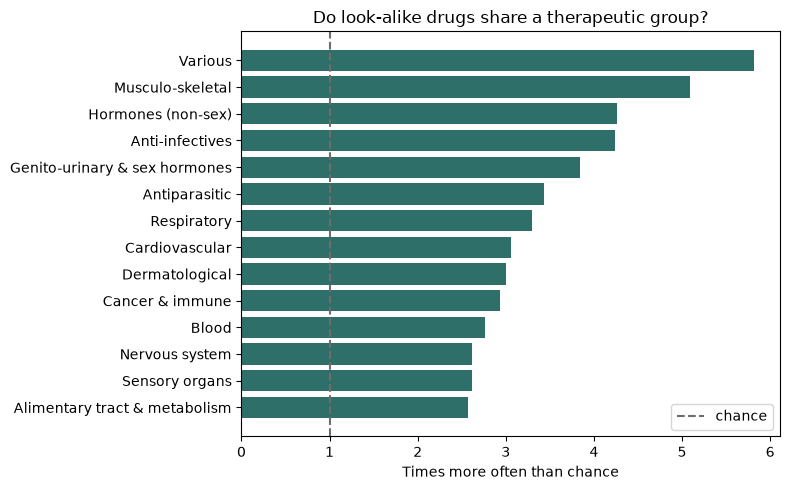

In [24]:
plt.figure(figsize=(8, 5))
plt.barh(results["name"], results["times_chance"], color="#2F6F6A")
plt.axvline(1, color="#6E6D6A", linestyle="--", label="chance")
plt.gca().invert_yaxis()                  # biggest bar on top
plt.xlabel("Times more often than chance")
plt.title("Do look-alike drugs share a therapeutic group?")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Save for later

Saved so the website and report don't need to rerun this.

In [25]:
results.to_csv("../data/processed/group_scores.csv", index=False)
print("saved")

saved
